# Лабораторная работа №1

Номер по списку: **3**, ПК: **3**, группа: **2**.

Варианты таблиц выбираются по кругу: (номер−1) % число строк + 1. Для ЛР3–4 N=ПК+группа; N не является номером по списку.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats, special
import pywt
plt.rcParams.update({'figure.figsize': (12,4), 'figure.dpi': 100,
                     'axes.grid': True, 'grid.alpha': .25})
number=3; pc=3; group=2
rng=np.random.default_rng(303)


## Равномерная и нормальная случайные величины
Конгруэнтный генератор: $s_{k+1}=(1664525s_k+1013904223)\bmod 2^{32}$, $U=(s+0.5)/2^{32}$.
Нормальная СВ получается произведением независимых релеевской и арксинусной СВ:
$Z_1=\sqrt{-2\ln U_1}\cos(2\pi U_2)$, $Z_2=\sqrt{-2\ln U_1}\sin(2\pi U_2)$; $X=\mu+\sigma Z$.
Здесь $\sigma=2$, $\mu=a=\lambda=3$; $Z_1,Z_2$ стандартные нормальные.
Структура: **LCG → U₁,U₂ → радиус и фаза → Z₁,Z₂ → μ+σZ → X**.
Нормировка гистограмм: $\hat p(x_i)=n_i/(N\Delta x_i)$; аналитическая плотность рассчитывается в центрах интервалов.

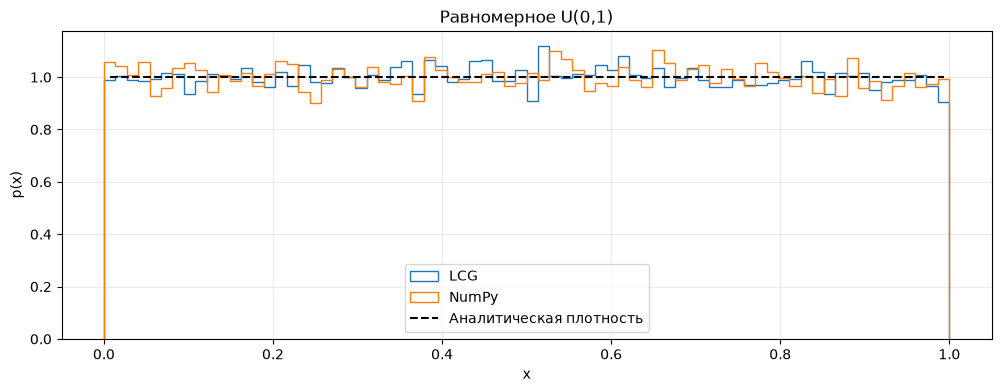

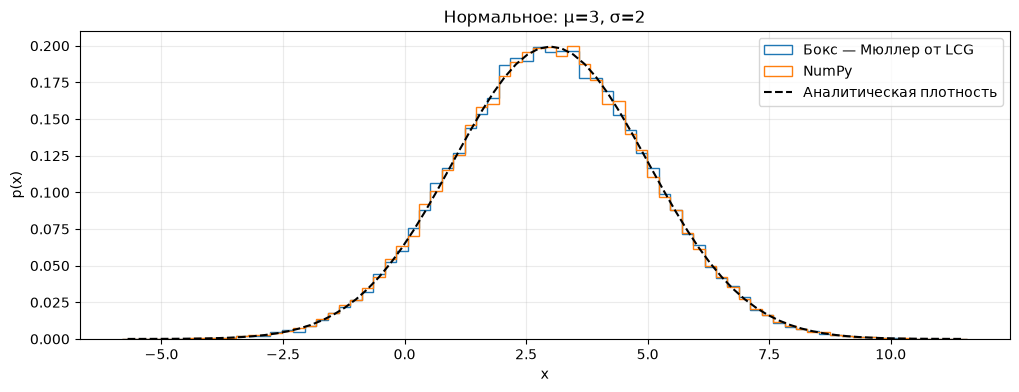

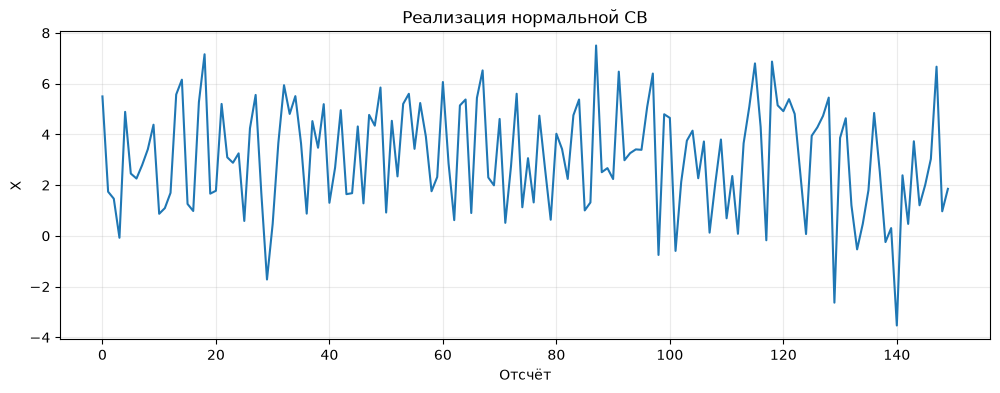

Оценки нормальной СВ: среднее, дисперсия: 2.988623088423972 3.999663810901081 ; теория: 3 4
Корреляция Z1,Z2: 0.004337914491246696


In [2]:
size=50000; sigma=group; mu=number
state=123456789
u=np.empty(2*size)
for k in range(len(u)):
    state=(1664525*state+1013904223) % 2**32
    u[k]=(state+.5)/2**32
u1,u2=u[::2],u[1::2]
r=np.sqrt(-2*np.log(u1)); phase=2*np.pi*u2
z1,z2=r*np.cos(phase),r*np.sin(phase)
x=mu+sigma*z1
xlib=rng.normal(mu,sigma,size)
def compare(samples,labels,dist,title):
    edges=np.linspace(min(s.min() for s in samples),max(s.max() for s in samples),75)
    centers=(edges[1:]+edges[:-1])/2
    fig,ax=plt.subplots()
    for s,l in zip(samples,labels): ax.hist(s,bins=edges,density=True,histtype='step',label=l)
    ax.plot(centers,dist.pdf(centers),'k--',label='Аналитическая плотность')
    ax.set(xlabel='x',ylabel='p(x)',title=title); ax.legend(); plt.show()
compare([u1,rng.uniform(size=size)],['LCG','NumPy'],stats.uniform(),'Равномерное U(0,1)')
compare([x,xlib],['Бокс — Мюллер от LCG','NumPy'],stats.norm(mu,sigma),f'Нормальное: μ={mu}, σ={sigma}')
fig,ax=plt.subplots(); ax.plot(x[:150]); ax.set(xlabel='Отсчёт',ylabel='X',title='Реализация нормальной СВ'); plt.show()
print('Оценки нормальной СВ: среднее, дисперсия:',x.mean(),x.var(),'; теория:',mu,sigma**2)
print('Корреляция Z1,Z2:',np.corrcoef(z1,z2)[0,1])

## Вариант 3: нормальное → показательный
$$Y=(Z_1^2+Z_2^2)/(2\lambda).$$
Структура: **Z₁,Z₂ → нелинейное преобразование → Y → гистограмма и моменты**.

$Z_1^2+Z_2^2\sim\chi^2_2$, поэтому $p(y)=\lambda e^{-\lambda y}$, $y\ge0$. Теория: $E[Y]=1/\lambda$, $D[Y]=1/\lambda^2$. Если исходные квадратуры имеют СКО σ, их сумму квадратов нужно дополнительно делить на σ².

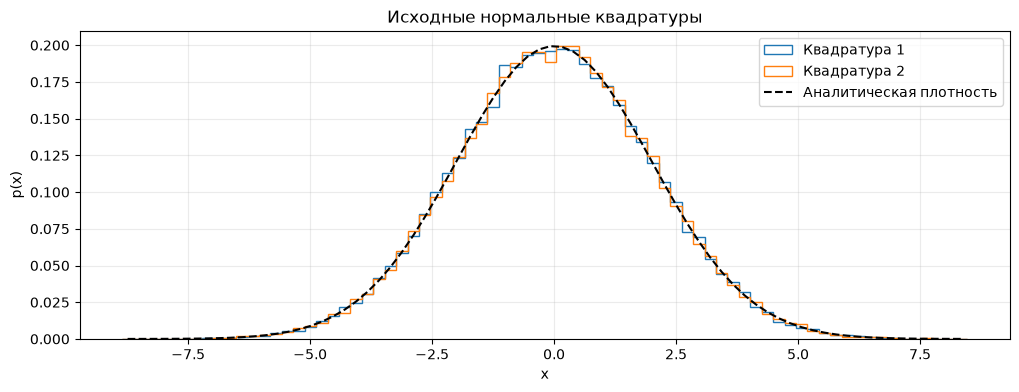

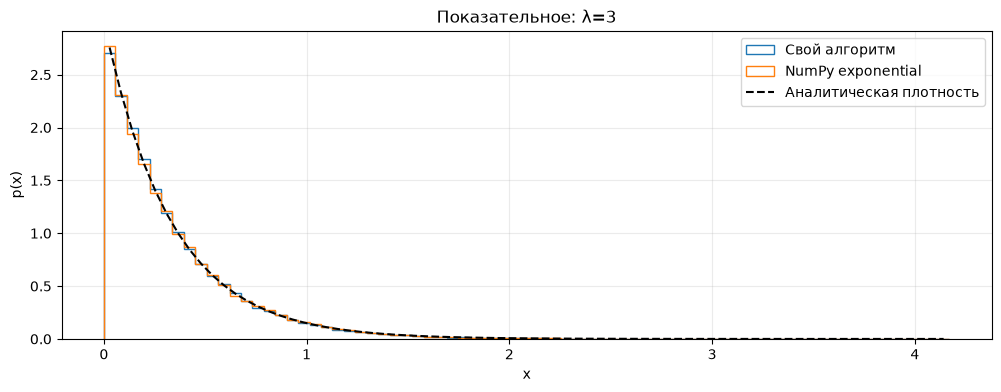

In [3]:
y=(z1*z1+z2*z2)/(2*number)
dist=stats.expon(scale=1/number)
ylib=rng.exponential(1/number,size)
compare([sigma*z1,sigma*z2],['Квадратура 1','Квадратура 2'],stats.norm(0,sigma),'Исходные нормальные квадратуры')
compare([y,ylib],['Свой алгоритм','NumPy exponential'],dist,f'Показательное: λ={number}')

Y: среднее / теория: 0.33333295151990694 0.3333333333333333
Y: дисперсия / теория: 0.11019512075734121 0.1111111111111111


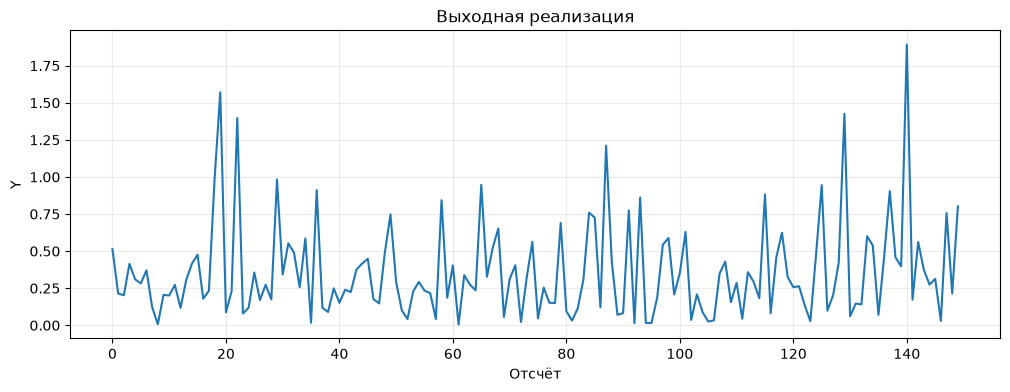

In [4]:
print('Y: среднее / теория:',y.mean(),dist.mean())
print('Y: дисперсия / теория:',y.var(),dist.var())
fig,ax=plt.subplots(); ax.plot(y[:150]); ax.set(xlabel='Отсчёт',ylabel='Y',title='Выходная реализация'); plt.show()

## Выводы
Получены равномерная, нормальная и показательный СВ; собственные алгоритмы сопоставлены с библиотечными и аналитической плотностью. Оценки моментов приведены выше, конечная выборка вызывает отклонения гистограмм от теории. Псевдослучайный LCG детерминирован, поэтому совпадение плотности само по себе не доказывает независимость.
Показательное распределение описывает мощность комплексного гауссовского шума в радиоприёмнике (сумму квадратов двух независимых квадратур).